# 09 — Figures for the README and report

**Purpose:** Produce the four figures and the descriptive table used in the README and the report, from the saved analysis table and model results. No new modeling happens here.

**Inputs:**
- `data/processed/analysis_oh_county.csv` (notebook 07): one row per county
- `outputs/nb_results_noise.csv` (notebook 07): rate ratios from the negative binomial models
- `data/large/boundaries/cb_2022_us_county_500k.zip`: Census county boundaries (see `data/README.md`)

**Outputs** (saved to `outputs/`):
| File | Shows |
|---|---|
| `fig1_noise_exposure_map.png` | Share of residents at ≥50 dBA, by county |
| `fig2_smr_map.png` | Standardized mortality ratio for CVD, by county |
| `fig3_forest_plot.png` | Rate ratios across the primary, sensitivity, and threshold models |
| `fig4_exposure_methods.png` | Internal-point vs. building-weighted exposure |
| `table1_county_characteristics.csv` | Median, IQR, and range of county characteristics |

**Color choices:** one blue ramp for magnitude (exposure), a blue–gray–red diverging scale centered on SMR = 1 for mortality, and a single blue for the pre-specified primary model with gray for every other model.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

PROCESSED  = Path("../data/processed")
OUTPUTS    = Path("../outputs")
BOUNDARIES = Path("../data/large/boundaries/cb_2022_us_county_500k.zip")

for name, p in [("analysis table", PROCESSED / "analysis_oh_county.csv"),
                ("model results", OUTPUTS / "nb_results_noise.csv"),
                ("county boundaries", BOUNDARIES)]:
    assert p.exists(), f"{name} not found: {p}"

# ---- Colors (light surface) ----
SURFACE   = "#fcfcfb"
INK       = "#0b0b0b"     # titles, values
INK_2     = "#52514e"     # subtitles, secondary marks
MUTED     = "#898781"     # axis labels
GRID      = "#e1e0d9"
BASELINE  = "#c3c2b7"
BLUE      = "#2a78d6"     # the single highlight color

# Sequential ramp for magnitude: one hue, light -> dark
SEQ_BLUE = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
# Diverging scale for SMR: blue = fewer deaths than expected, red = more, gray = about as expected.
# The red steps are matched in lightness to the blue steps so neither side looks stronger.
DIV = ["#104281", "#2a78d6", "#86b6ef", "#f0efec", "#ea9a93", "#c74845", "#762221"]

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Inter", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 9,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2,
    "axes.edgecolor": BASELINE, "axes.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "figure.dpi": 110, "savefig.dpi": 200,
})

def add_title(fig, title, subtitle, x=0.02, y=0.975):
    # Left-aligned title and subtitle above the plot
    fig.text(x, y, title, fontsize=12, fontweight="semibold", color=INK, va="top", ha="left")
    fig.text(x, y - 0.058, subtitle, fontsize=9, color=INK_2, va="top", ha="left", linespacing=1.35)

def save(fig, filename):
    path = OUTPUTS / filename
    fig.savefig(path, bbox_inches="tight", pad_inches=0.15)
    print("Saved", path)

## Load the analysis table and county boundaries

In [2]:
df = pd.read_csv(PROCESSED / "analysis_oh_county.csv", dtype={"county_fips": str})
assert len(df) == 88
df["name"] = df["county"].str.replace(" County, OH", "", regex=False)

results = pd.read_csv(OUTPUTS / "nb_results_noise.csv", index_col=0)
assert results["converged"].all()

counties = gpd.read_file(BOUNDARIES)
oh = (counties.loc[counties["STATEFP"] == "39", ["GEOID", "geometry"]]
              .rename(columns={"GEOID": "county_fips"})
              .to_crs("EPSG:32617"))                      # UTM zone 17N: undistorted shapes for Ohio
gdf = oh.merge(df, on="county_fips", how="inner", validate="one_to_one")
assert len(gdf) == 88

state_outline = gdf.dissolve().boundary

def county_map(column, edges, colors, class_labels, title, subtitle, legend_title, label_names, filename):
    # Choropleth with discrete classes: edges are the class boundaries, colors one per class
    assert len(colors) == len(edges) + 1 == len(class_labels)
    cls = np.digitize(gdf[column].to_numpy(), edges)       # class index 0..len(edges) per county
    fig, ax = plt.subplots(figsize=(7.2, 6.4))
    fig.subplots_adjust(left=0.01, right=0.76, top=0.84, bottom=0.02)
    gdf.plot(ax=ax, color=[colors[i] for i in cls], edgecolor=SURFACE, linewidth=0.7)
    state_outline.plot(ax=ax, color=BASELINE, linewidth=0.9)

    # Label a few counties only; text is white or near-black depending on the fill
    for _, row in gdf[gdf["name"].isin(label_names)].iterrows():
        fill = colors[np.digitize(row[column], edges)]
        r, g, b = mpl.colors.to_rgb(fill)
        dark_fill = (0.2126 * r + 0.7152 * g + 0.0722 * b) < 0.42
        pt = row.geometry.representative_point()
        ax.annotate(row["name"], (pt.x, pt.y), ha="center", va="center", fontsize=6.3,
                    color="#ffffff" if dark_fill else INK)

    handles = [Patch(facecolor=c, edgecolor="none", label=l) for c, l in zip(colors, class_labels)]
    leg = ax.legend(handles=handles[::-1], title=legend_title, loc="center left",
                    bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=8.5,
                    title_fontsize=8.5, handlelength=1.3, handleheight=1.1, labelspacing=0.45)
    leg._legend_box.align = "left"
    plt.setp(leg.get_title(), color=INK_2)
    for text, n in zip(leg.get_texts(), np.bincount(cls, minlength=len(colors))[::-1]):
        text.set_text(f"{text.get_text()}   ({n})")
        text.set_color(INK)

    ax.set_axis_off()
    add_title(fig, title, subtitle)
    save(fig, filename)
    plt.show()

## Figure 1 — Noise exposure by county

Share of residents living at ≥50 dBA (the pre-specified primary exposure). Counties are grouped into five classes; the number in parentheses in the legend is how many counties fall in each class.

Saved ../outputs/fig1_noise_exposure_map.png


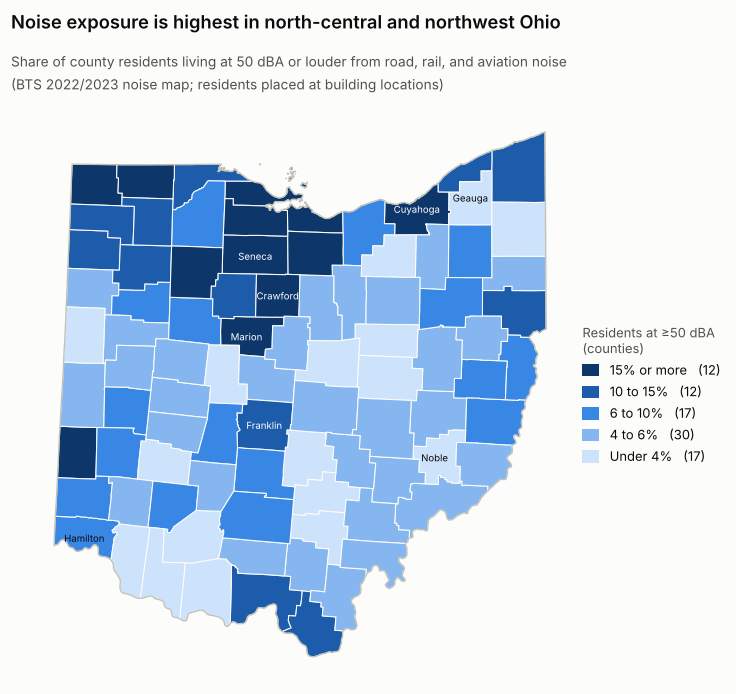

In [3]:
gdf["noise_ge50_pct"] = gdf["noise_ge50"] * 100

county_map(
    column="noise_ge50_pct",
    edges=[4, 6, 10, 15],
    colors=SEQ_BLUE,
    class_labels=["Under 4%", "4 to 6%", "6 to 10%", "10 to 15%", "15% or more"],
    title="Noise exposure is highest in north-central and northwest Ohio",
    subtitle=("Share of county residents living at 50 dBA or louder from road, rail, and aviation noise\n"
              "(BTS 2022/2023 noise map; residents placed at building locations)"),
    legend_title="Residents at ≥50 dBA\n(counties)",
    label_names=["Seneca", "Crawford", "Marion", "Cuyahoga", "Franklin", "Hamilton", "Geauga", "Noble"],
    filename="fig1_noise_exposure_map.png",
)

## Figure 2 — CVD mortality by county (SMR)

The standardized mortality ratio is observed CVD deaths divided by the deaths expected from the county's age structure. Gray counties are within 5% of expected; blue counties have fewer deaths than expected and red counties more.

Saved ../outputs/fig2_smr_map.png


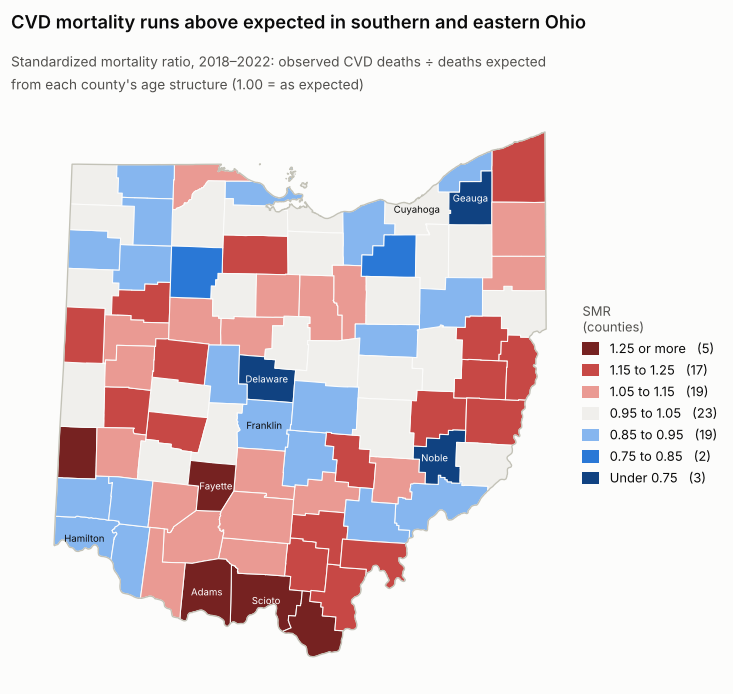

In [4]:
county_map(
    column="smr",
    edges=[0.75, 0.85, 0.95, 1.05, 1.15, 1.25],
    colors=DIV,
    class_labels=["Under 0.75", "0.75 to 0.85", "0.85 to 0.95", "0.95 to 1.05",
                  "1.05 to 1.15", "1.15 to 1.25", "1.25 or more"],
    title="CVD mortality runs above expected in southern and eastern Ohio",
    subtitle=("Standardized mortality ratio, 2018–2022: observed CVD deaths ÷ deaths expected\n"
              "from each county's age structure (1.00 = as expected)"),
    legend_title="SMR\n(counties)",
    label_names=["Adams", "Fayette", "Scioto", "Noble", "Delaware", "Geauga",
                 "Cuyahoga", "Franklin", "Hamilton"],
    filename="fig2_smr_map.png",
)

## Figure 3 — Rate ratios across models

The top block shows the ≥50 dBA exposure per 5 percentage points under each specification. The bottom block compares the three thresholds per interquartile range (IQR), the only scale on which they are comparable. The per-IQR values are computed the same way as in notebook 07.

Saved ../outputs/fig3_forest_plot.png


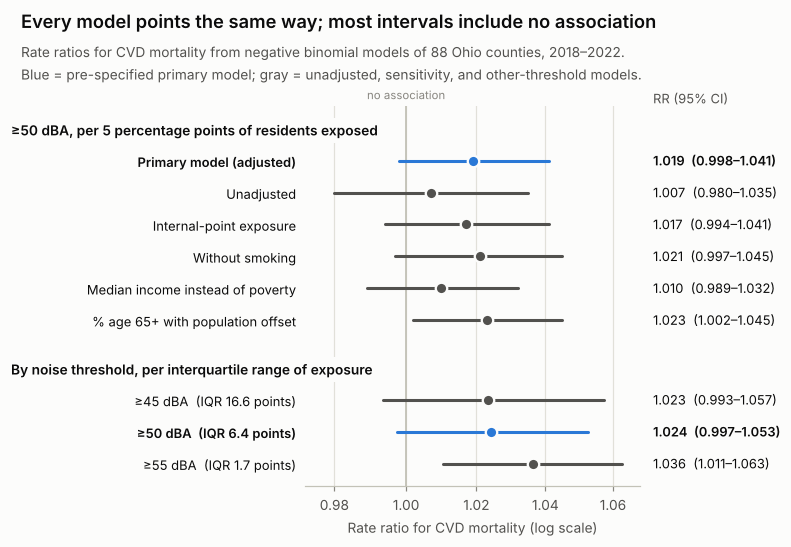

In [5]:
# ---- Rows of the plot ----
IQR_PP = {t: (df[f"noise_ge{t}"].quantile(0.75) - df[f"noise_ge{t}"].quantile(0.25)) * 100
          for t in [45, 50, 55]}

def per_iqr(name, t):
    k = IQR_PP[t] / 5                                      # number of 5-point steps in one IQR
    rr, lo, hi = results.loc[name, ["RR", "CI_low", "CI_high"]]
    return rr**k, lo**k, hi**k

rows = [
    # (label, RR, CI low, CI high, is the pre-specified primary model)
    ("header", "≥50 dBA, per 5 percentage points of residents exposed"),
    ("Primary model (adjusted)",               *results.loc["Primary (>=50 dBA)",                 ["RR", "CI_low", "CI_high"]], True),
    ("Unadjusted",                             *results.loc["Unadjusted (>=50 dBA)",              ["RR", "CI_low", "CI_high"]], False),
    ("Internal-point exposure",                *results.loc["Sens: internal-point exposure",      ["RR", "CI_low", "CI_high"]], False),
    ("Without smoking",                        *results.loc["Sens: without smoking",              ["RR", "CI_low", "CI_high"]], False),
    ("Median income instead of poverty",       *results.loc["Sens: income instead of poverty",    ["RR", "CI_low", "CI_high"]], False),
    ("% age 65+ with population offset",       *results.loc["Sens: % 65+ with population offset", ["RR", "CI_low", "CI_high"]], False),
    ("header", "By noise threshold, per interquartile range of exposure"),
    (f"≥45 dBA  (IQR {IQR_PP[45]:.1f} points)", *per_iqr("Secondary: >=45 dBA", 45), False),
    (f"≥50 dBA  (IQR {IQR_PP[50]:.1f} points)", *per_iqr("Primary (>=50 dBA)", 50), True),
    (f"≥55 dBA  (IQR {IQR_PP[55]:.1f} points)", *per_iqr("Secondary: >=55 dBA", 55), False),
]

fig, ax = plt.subplots(figsize=(7.6, 5.0))
fig.subplots_adjust(left=0.36, right=0.76, top=0.80, bottom=0.11)

y = 0.0
yticks, ylabels, primary_flags = [], [], []
for row in rows:
    if row[0] == "header":
        y -= 0.55
        ax.text(-0.88, y, row[1], transform=ax.get_yaxis_transform(), fontsize=9,
                fontweight="semibold", color=INK, va="center", ha="left", zorder=5,
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=2.5))
        y -= 0.95
        continue
    label, rr, lo, hi, primary = row
    color = BLUE if primary else INK_2
    ax.plot([lo, hi], [y, y], color=color, linewidth=2, solid_capstyle="round", zorder=2)
    ax.plot(rr, y, "o", color=color, markersize=7.5, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
    ax.text(1.04, y, f"{rr:.3f}  ({lo:.3f}–{hi:.3f})", transform=ax.get_yaxis_transform(),
            fontsize=8.5, color=INK, va="center", ha="left",
            fontweight="semibold" if primary else "normal")
    yticks.append(y); ylabels.append(label); primary_flags.append(primary)
    y -= 1.0

ax.axvline(1.0, color=BASELINE, linewidth=1.2, zorder=1)        # no association
ax.set_xscale("log")
ax.set_xlim(0.972, 1.068)
ticks = [0.98, 1.00, 1.02, 1.04, 1.06]
ax.set_xticks(ticks); ax.set_xticklabels([f"{t:.2f}" for t in ticks])
ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.set_xlabel("Rate ratio for CVD mortality (log scale)")
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)

ax.set_yticks(yticks); ax.set_yticklabels(ylabels, fontsize=8.5)
for tick, primary in zip(ax.get_yticklabels(), primary_flags):
    tick.set_color(INK)
    tick.set_fontweight("semibold" if primary else "normal")
ax.tick_params(axis="y", length=0, pad=6)
ax.set_ylim(y + 0.3, 0.2)
for side in ["left", "right", "top"]:
    ax.spines[side].set_visible(False)

ax.text(1.04, 1.0, "RR (95% CI)", transform=ax.transAxes, fontsize=8.5, color=INK_2, va="bottom", ha="left")
ax.text(1.0, 1.012, "no association", transform=ax.get_xaxis_transform(), fontsize=7.5,
        color=MUTED, va="bottom", ha="center")

add_title(fig, "Every model points the same way; most intervals include no association",
          "Rate ratios for CVD mortality from negative binomial models of 88 Ohio counties, 2018–2022.\n"
          "Blue = pre-specified primary model; gray = unadjusted, sensitivity, and other-threshold models.",
          y=0.975)
save(fig, "fig3_forest_plot.png")
plt.show()

## Figure 4 — Internal-point vs. building-weighted exposure

Each point is a county. Points above the diagonal have higher exposure when residents are placed at buildings (notebook 04) than at census block internal points (notebook 03).

Saved ../outputs/fig4_exposure_methods.png


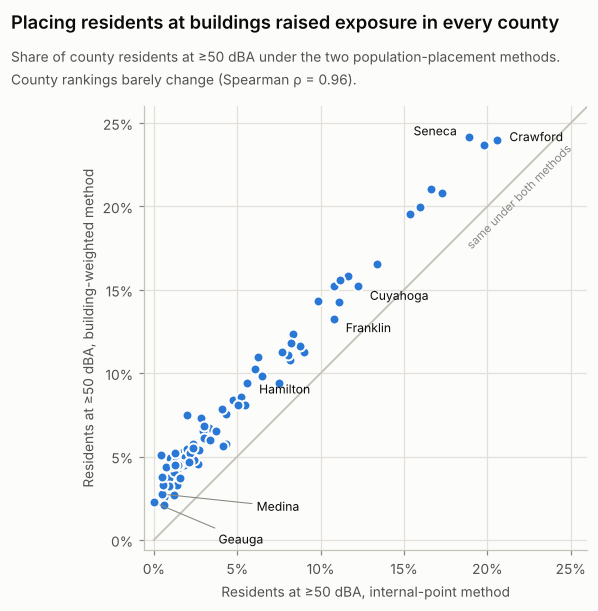

In [6]:
x = df["noisept_ge50"] * 100
y = df["noise_ge50"] * 100
rho = x.rank().corr(y.rank())                 # Spearman correlation: agreement in county rankings
n_higher = int((y > x).sum())

fig, ax = plt.subplots(figsize=(6.2, 5.6))
fig.subplots_adjust(left=0.11, right=0.97, top=0.82, bottom=0.10)

lim = 26
ax.plot([0, lim], [0, lim], color=BASELINE, linewidth=1.2, zorder=1)
ax.text(24.6, 23.9, "same under both methods", fontsize=7.5, color=MUTED, rotation=45,
        ha="right", va="top", rotation_mode="anchor")
ax.scatter(x, y, s=42, color=BLUE, edgecolor=SURFACE, linewidth=1.3, zorder=3)

# Label a few counties. Geauga and Medina sit in the dense cluster, so their labels
# are moved into the empty area below the diagonal and joined by a thin leader line.
offsets = {"Geauga": (42, -24), "Medina": (62, -8), "Crawford": (8, 2), "Seneca": (-8, 4),
           "Cuyahoga": (8, -6), "Franklin": (8, -6), "Hamilton": (8, -4)}
for name, (dx, dy) in offsets.items():
    r = df[df["name"] == name].iloc[0]
    leader = dict(arrowstyle="-", color=MUTED, linewidth=0.7, shrinkA=1, shrinkB=4) if abs(dx) > 20 else None
    ax.annotate(name, (r["noisept_ge50"] * 100, r["noise_ge50"] * 100), xytext=(dx, dy),
                textcoords="offset points", fontsize=8, color=INK, arrowprops=leader,
                ha="left" if dx > 0 else "right", va="center")

ax.set_xlim(-0.6, lim); ax.set_ylim(-0.6, lim)
ax.set_aspect("equal")
ticks = [0, 5, 10, 15, 20, 25]
ax.set_xticks(ticks); ax.set_yticks(ticks)
ax.set_xticklabels([f"{t}%" for t in ticks]); ax.set_yticklabels([f"{t}%" for t in ticks])
ax.set_xlabel("Residents at ≥50 dBA, internal-point method")
ax.set_ylabel("Residents at ≥50 dBA, building-weighted method")
ax.grid(color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for side in ["right", "top"]:
    ax.spines[side].set_visible(False)

where = "every county" if n_higher == len(df) else f"{n_higher} of {len(df)} counties"
add_title(fig, f"Placing residents at buildings raised exposure in {where}",
          f"Share of county residents at ≥50 dBA under the two population-placement methods.\n"
          f"County rankings barely change (Spearman ρ = {rho:.2f}).", y=0.975)
save(fig, "fig4_exposure_methods.png")
plt.show()

## Table 1 — County characteristics

Descriptive statistics quoted in the report: the median, interquartile range, and range across the 88 counties, plus statewide exposure shares (population-weighted, from notebook 04's output).

In [7]:
def describe_row(label, s, scale=1, decimals=1):
    q1, med, q3 = (s.quantile([0.25, 0.5, 0.75]) * scale)
    return {"Characteristic": label,
            "Median": round(med, decimals),
            "IQR": f"{q1:.{decimals}f} to {q3:.{decimals}f}",
            "Range": f"{s.min() * scale:.{decimals}f} to {s.max() * scale:.{decimals}f}"}

table1 = pd.DataFrame([
    describe_row("CVD deaths, 2018–2022", df["deaths"], decimals=0),
    describe_row("Expected CVD deaths", df["expected"], decimals=0),
    describe_row("Standardized mortality ratio", df["smr"], decimals=2),
    describe_row("Residents at ≥45 dBA (%)", df["noise_ge45"], 100),
    describe_row("Residents at ≥50 dBA (%)", df["noise_ge50"], 100),
    describe_row("Residents at ≥55 dBA (%)", df["noise_ge55"], 100),
    describe_row("Urban population (%)", df["pct_urban"], 100),
    describe_row("Below poverty (%)", df["pct_poverty"], 100),
    describe_row("Non-Hispanic Black (%)", df["pct_black_nh"], 100),
    describe_row("Current smoking, age-adjusted (%)", df["pct_smoking"], 100),
    describe_row("PM2.5, 2018–2022 mean (µg/m³)", df["pm25"], decimals=2),
    describe_row("CHD prevalence, age-adjusted (%)", df["CHD"]),
])
table1.to_csv(OUTPUTS / "table1_county_characteristics.csv", index=False)
table1

,Characteristic,Median,IQR,Range
0,"CVD deaths, 2018–2022",1037.00,638 to 2124,216 to 23507
1,Expected CVD deaths,972.00,626 to 2123,195 to 23149
2,Standardized mortality ratio,1.03,0.94 to 1.15,0.62 to 1.38
3,Residents at ≥45 dBA (%),15.40,9.1 to 25.6,4.1 to 54.6
4,Residents at ≥50 dBA (%),5.70,4.5 to 10.8,2.1 to 24.2
5,Residents at ≥55 dBA (%),2.00,1.4 to 3.2,0.3 to 7.7
6,Urban population (%),44.60,28.4 to 66.8,0.0 to 99.4
7,Below poverty (%),12.90,10.1 to 16.1,4.5 to 24.4
8,Non-Hispanic Black (%),1.90,0.9 to 4.5,0.1 to 28.7
9,"Current smoking, age-adjusted (%)",17.60,15.6 to 19.4,9.9 to 23.3


In [8]:
# Statewide share of residents above each threshold (building-weighted)
noise_b = pd.read_csv(PROCESSED / "noise_oh_county_2022_bldg.csv", dtype={"county_fips": str})
total = noise_b["POP20"].sum()
assert np.isclose(total, 11_799_448)
for t in [45, 50, 55]:
    print(f"Ohio residents at >= {t} dBA: {noise_b[f'pop_ge{t}'].sum() / total:.1%}")
print(f"Total CVD deaths: {df['deaths'].sum():,}")

Ohio residents at >= 45 dBA: 23.6%
Ohio residents at >= 50 dBA: 9.1%
Ohio residents at >= 55 dBA: 2.5%
Total CVD deaths: 198,052
